# Experiments

The training runs are made by `experiments/run.py` and saved in `results/`, one file per run with its configuration, its learning curves and the evaluation of the final policy. This notebook only reads them. To redo a group of runs:

```bash
uv run python experiments/run.py tuning
```

The hyperparameters are chosen on 1000 validation episodes (`VALIDATION_SEED`), so the tuning below shows validation returns. All the other results are on 1000 different test episodes (`TEST_SEED`), so they do not benefit from the choice.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

RESULTS = Path("../results")


def load(experiment):
    """All the runs of an experiment, each a dict with its configuration and its arrays."""
    runs = []
    for path in sorted((RESULTS / experiment).glob("*.npz")):
        data = np.load(path)
        config = json.loads(str(data["config"]))
        runs.append(config | {key: data[key] for key in data.files if key != "config"})
    return runs


def mean_and_error(values):
    """Mean and standard error of the mean over the seeds."""
    values = np.asarray(values, dtype=float)
    return values.mean(), values.std(ddof=1) / np.sqrt(len(values))

## Tuning

GPOMDP with its baseline at m = 75 kg and C = 0.5. The batch size n and the initial step size lr of Adam vary, with the same budget of 100 000 training episodes for every run (K = 100 000 / n iterations), and 3 seeds for each pair. The score of a pair is the return of its final policies on the validation episodes, averaged over the seeds.

In [2]:
tuning = load("tuning")
batch_sizes = sorted({run["batch_size"] for run in tuning})
lrs = sorted({run["lr"] for run in tuning})
score = {}
for n in batch_sizes:
    for lr in lrs:
        values = [r["validation_return"] for r in tuning if r["batch_size"] == n and r["lr"] == lr]
        score[n, lr] = mean_and_error(values)

print("validation return in thousands, mean ± standard error over 3 seeds")
print(f"{'n':>4} {'K':>5} " + "".join(f"{f'lr {lr:g}':>15}" for lr in lrs))
for n in batch_sizes:
    cells = "".join(f"{score[n, lr][0] / 1e3:8.1f} ± {score[n, lr][1] / 1e3:4.1f}" for lr in lrs)
    print(f"{n:>4} {100_000 // n:>5} {cells}")
best_n, best_lr = max(score, key=lambda key: score[key][0])
print(f"\nbest: n = {best_n}, lr = {best_lr:g}")

validation return in thousands, mean ± standard error over 3 seeds
   n     K        lr 0.001       lr 0.003        lr 0.01        lr 0.03         lr 0.1
  50  2000   -138.7 ±  3.1   -78.8 ±  3.3   -64.3 ±  0.3   -65.6 ±  0.6   -75.0 ±  3.0
 100  1000   -172.2 ±  0.4  -111.1 ±  2.3   -67.5 ±  0.5   -65.5 ±  0.8  -102.6 ± 29.1
 200   500   -191.3 ±  0.4  -141.3 ±  1.8   -83.1 ±  4.4   -71.3 ±  6.0  -102.3 ±  7.6

best: n = 50, lr = 0.01


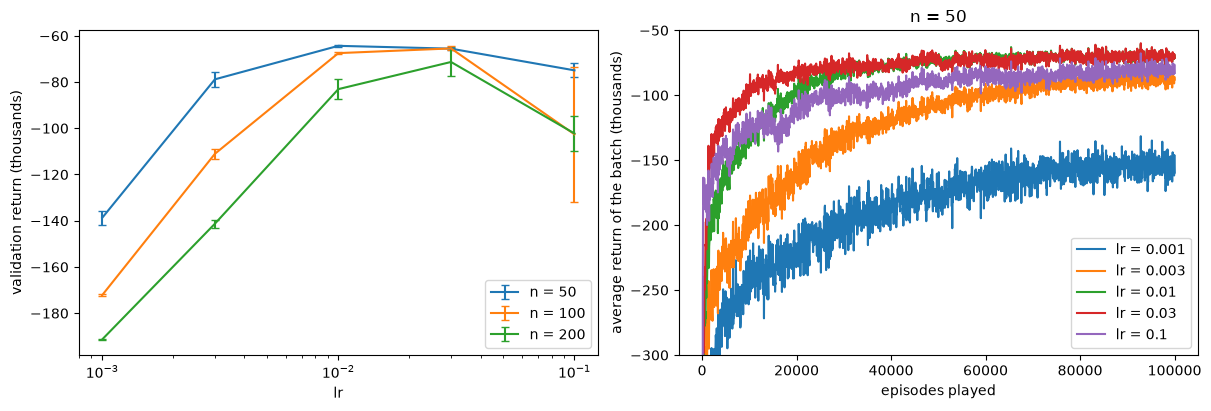

In [3]:
fig, (ax_score, ax_curves) = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for n in batch_sizes:
    means = [score[n, lr][0] / 1e3 for lr in lrs]
    errors = [score[n, lr][1] / 1e3 for lr in lrs]
    ax_score.errorbar(lrs, means, yerr=errors, capsize=3, label=f"n = {n}")
ax_score.set_xscale("log")
ax_score.set_xlabel("lr")
ax_score.set_ylabel("validation return (thousands)")
ax_score.legend()

for lr in lrs:  # learning curves at the best n, mean over the seeds
    curves = [r["return"] for r in tuning if r["batch_size"] == best_n and r["lr"] == lr]
    episodes = best_n * np.arange(1, len(curves[0]) + 1)
    ax_curves.plot(episodes, np.mean(curves, axis=0) / 1e3, label=f"lr = {lr:g}")
ax_curves.set_xlabel("episodes played")
ax_curves.set_ylabel("average return of the batch (thousands)")
ax_curves.set_ylim(-300, -50)  # the first iterations fall below
ax_curves.set_title(f"n = {best_n}")
ax_curves.legend()
plt.show()

The chosen pair is n = 50 and lr = 0.01, the defaults of `Config`. The first guess of `training.ipynb` (n = 100, lr = 0.001) is far behind: with a step that decreases to zero, every parameter can move by at most about 0.5 in the whole training, too little. lr = 0.1 is unstable: its results change a lot from seed to seed. With the same budget, a smaller n is better: more updates count more than less noisy gradients.

In the curves on the right, every run starts below the plot, at about −630 000 with the initial policy (pure noise). With lr = 0.03 and 0.1 the second iteration falls much lower: the first step of Adam moves every parameter by about lr, and with a large lr that is enough to push the robot far from the rink for one iteration (a return of −34 million with lr = 0.1). The next steps bring it back.